# HR Analytics – TechNova Partners
## Analyse des causes de démission

## Importations

In [1]:
import warnings
warnings.filterwarnings('ignore')

# Données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve,
    RocCurveDisplay, f1_score, recall_score, precision_score
)

# Déséquilibre des classes
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Hyperparamètres
from sklearn.model_selection import RandomizedSearchCV

# Interprétabilité
import shap

# Style global
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

PALETTE = {'Non': '#4C72B0', 'Oui': '#DD8452'}

## Étape 1 — Chargement & Exploration initiale des données

Je commence par charger séparément chacun des trois fichiers sources, puis je réalise
des statistiques descriptives simples pour comprendre leur contenu avant toute transformation.


In [2]:
df_sirh    = pd.read_csv('../data/extrait_sirh.csv')
df_eval    = pd.read_csv('../data/extrait_eval.csv')
df_sondage = pd.read_csv('../data/extrait_sondage.csv')

print(f"SIRH    : {df_sirh.shape[0]:>4} lignes × {df_sirh.shape[1]} colonnes")
print(f"Eval    : {df_eval.shape[0]:>4} lignes × {df_eval.shape[1]} colonnes")
print(f"Sondage : {df_sondage.shape[0]:>4} lignes × {df_sondage.shape[1]} colonnes")


SIRH    : 1470 lignes × 12 colonnes
Eval    : 1470 lignes × 10 colonnes
Sondage : 1470 lignes × 12 colonnes


### 1.1 Extrait SIRH

J'examine les premières lignes et les types de données du fichier SIRH.

In [3]:
display(df_sirh.head(3))


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0


In [4]:
# Je construis un tableau synthétique : type, nb de valeurs manquantes, nb de valeurs uniques
def resumer_df(df):
    return pd.DataFrame({
        'dtype'         : df.dtypes,
        'manquants'     : df.isna().sum(),
        'manquants_%'   : (df.isna().mean() * 100).round(1),
        'nb_uniques'    : df.nunique(),
    })

display(resumer_df(df_sirh))


,dtype,manquants,manquants_%,nb_uniques
id_employee,int64,0,0.0,1470
age,int64,0,0.0,43
genre,object,0,0.0,2
revenu_mensuel,int64,0,0.0,1349
statut_marital,object,0,0.0,3
departement,object,0,0.0,3
poste,object,0,0.0,9
nombre_experiences_precedentes,int64,0,0.0,10
nombre_heures_travailless,int64,0,0.0,1
annee_experience_totale,int64,0,0.0,40


In [5]:
display(df_sirh.describe().round(2))


,id_employee,age,revenu_mensuel,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
count,1470.00,1470.00,1470.00,1470.00,1470.0,1470.00,1470.00,1470.00
mean,1024.87,36.92,6502.93,2.69,80.0,11.28,7.01,4.23
std,602.02,9.14,4707.96,2.50,0.0,7.78,6.13,3.62
min,1.00,18.00,1009.00,0.00,80.0,0.00,0.00,0.00
25%,491.25,30.00,2911.00,1.00,80.0,6.00,3.00,2.00
50%,1020.50,36.00,4919.00,2.00,80.0,10.00,5.00,3.00
75%,1555.75,43.00,8379.00,4.00,80.0,15.00,9.00,7.00
max,2068.00,60.00,19999.00,9.00,80.0,40.00,40.00,18.00


### 1.2 Extrait Évaluations de performance

In [6]:
display(df_eval.head(3))
display(resumer_df(df_eval))


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %


,dtype,manquants,manquants_%,nb_uniques
satisfaction_employee_environnement,int64,0,0.0,4
note_evaluation_precedente,int64,0,0.0,4
niveau_hierarchique_poste,int64,0,0.0,5
satisfaction_employee_nature_travail,int64,0,0.0,4
satisfaction_employee_equipe,int64,0,0.0,4
satisfaction_employee_equilibre_pro_perso,int64,0,0.0,4
eval_number,object,0,0.0,1470
note_evaluation_actuelle,int64,0,0.0,2
heure_supplementaires,object,0,0.0,2
augementation_salaire_precedente,object,0,0.0,15


In [7]:
display(df_eval.describe().round(2))


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle
count,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00
mean,2.72,2.73,2.06,2.73,2.71,2.76,3.15
std,1.09,0.71,1.11,1.10,1.08,0.71,0.36
min,1.00,1.00,1.00,1.00,1.00,1.00,3.00
25%,2.00,2.00,1.00,2.00,2.00,2.00,3.00
50%,3.00,3.00,2.00,3.00,3.00,3.00,3.00
75%,4.00,3.00,3.00,4.00,4.00,3.00,3.00
max,4.00,4.00,5.00,4.00,4.00,4.00,4.00


### 1.3 Extrait Sondage bien-être

C'est dans ce fichier que se trouve ma variable cible `a_quitte_l_entreprise`.

In [8]:
display(df_sondage.head(3))
display(resumer_df(df_sondage))


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0


,dtype,manquants,manquants_%,nb_uniques
a_quitte_l_entreprise,object,0,0.0,2
nombre_participation_pee,int64,0,0.0,4
nb_formations_suivies,int64,0,0.0,7
nombre_employee_sous_responsabilite,int64,0,0.0,1
code_sondage,int64,0,0.0,1470
distance_domicile_travail,int64,0,0.0,29
niveau_education,int64,0,0.0,5
domaine_etude,object,0,0.0,6
ayant_enfants,object,0,0.0,1
frequence_deplacement,object,0,0.0,3


In [9]:
# Distribution de la variable cible
vc = df_sondage['a_quitte_l_entreprise'].value_counts()
display(pd.DataFrame({
    'Effectif'     : vc,
    'Pourcentage %': (vc / len(df_sondage) * 100).round(1)
}))


,Effectif,Pourcentage %
a_quitte_l_entreprise,,
Non,1233,83.9
Oui,237,16.1


> **Observation :** Je constate un **déséquilibre des classes** : seulement ~16 % des employés
ont quitté l'entreprise.

## Étape 2 — Nettoyage & Construction du DataFrame central

### 2.1 Nettoyage des colonnes

J'utilise `.apply()` pour harmoniser les colonnes qualitatives et `pd.to_numeric()` pour les colonnes numériques.
Je crée aussi la clé de jointure `id_employee` dans le fichier évaluations, en extrayant le numéro de `eval_number`.


In [10]:
# SIRH : nettoyage des colonnes texte
cols_texte_sirh = ['genre', 'statut_marital', 'departement', 'poste']
for col in cols_texte_sirh:
    df_sirh[col] = df_sirh[col].apply(lambda x: str(x).strip() if pd.notna(x) else np.nan)

# EVAL : extraction de la clé numérique + nettoyage augmentation
df_eval['id_employee'] = (
    df_eval['eval_number']
    .apply(lambda x: int(str(x).replace('E_', '')))
)

# augmentation_salaire_precedente est une chaîne → je la convertis en float
df_eval['augementation_salaire_precedente'] = (
    df_eval['augementation_salaire_precedente']
    .apply(lambda x: float(str(x).replace('%', '').strip()))
)

# SONDAGE : nettoyage des colonnes texte
cols_texte_sondage = ['a_quitte_l_entreprise', 'domaine_etude',
                      'ayant_enfants', 'frequence_deplacement']
for col in cols_texte_sondage:
    df_sondage[col] = df_sondage[col].apply(lambda x: str(x).strip() if pd.notna(x) else np.nan)


### 2.2 Identification des clés de jointure

| Fichier | Clé |
|---------|-----|
| SIRH | `id_employee` |
| Évaluations | `id_employee` (extrait de `eval_number`) |
| Sondage | `code_sondage` (correspond à `id_employee`) |

Je choisis une jointure **inner** pour garder uniquement les employés présents dans les 3 sources.


In [11]:
# Vérification avant jointure
print(f"IDs uniques SIRH    : {df_sirh['id_employee'].nunique()}")
print(f"IDs uniques Eval    : {df_eval['id_employee'].nunique()}")
print(f"IDs uniques Sondage : {df_sondage['code_sondage'].nunique()}")
ids_communs = set(df_sirh['id_employee']) & set(df_eval['id_employee']) & set(df_sondage['code_sondage'])
print(f"IDs communs aux 3   : {len(ids_communs)}")


IDs uniques SIRH    : 1470
IDs uniques Eval    : 1470
IDs uniques Sondage : 1470
IDs communs aux 3   : 1470


In [12]:
# Jointure en deux étapes
df = (
    df_sirh
    .merge(df_eval,    on='id_employee',                    how='inner')
    .merge(df_sondage, left_on='id_employee', right_on='code_sondage', how='inner')
)

# Je supprime les colonnes redondantes créées par la jointure
df = df.drop(columns=['eval_number', 'code_sondage', 'ayant_enfants'])
# 'ayant_enfants' ne contient qu'une seule modalité (Y) → aucun pouvoir discriminant

print(f"DataFrame central : {df.shape[0]} lignes × {df.shape[1]} colonnes")
display(df.head(3))


DataFrame central : 1470 lignes × 31 colonnes


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,...,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,...,Oui,0,0,1,1,2,Infra & Cloud,Occasionnel,0,5
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,...,Non,1,3,1,8,1,Infra & Cloud,Frequent,1,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,...,Oui,0,3,1,2,2,Autre,Occasionnel,0,0


### 2.3 Statistiques descriptives sur le DataFrame central

In [13]:
display(df.describe(include='all').T.round(2))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_employee,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
genre,1470,2,M,882,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenu_mensuel,1470.0,NaN,NaN,NaN,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.0,19999.0
statut_marital,1470,3,Marié(e),673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departement,1470,3,Consulting,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
poste,1470,9,Cadre Commercial,326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre_experiences_precedentes,1470.0,NaN,NaN,NaN,2.693197,2.498009,0.0,1.0,2.0,4.0,9.0
nombre_heures_travailless,1470.0,NaN,NaN,NaN,80.0,0.0,80.0,80.0,80.0,80.0,80.0
annee_experience_totale,1470.0,NaN,NaN,NaN,11.279592,7.780782,0.0,6.0,10.0,15.0,40.0


### 2.4 Analyse exploratoire — Employés partis vs. restants

Je compare maintenant les deux populations pour faire ressortir des différences clés.

In [14]:
# Variables quantitatives : moyennes par statut
cols_quanti = [
    'age', 'revenu_mensuel', 'annees_dans_l_entreprise',
    'annees_dans_le_poste_actuel', 'annee_experience_totale',
    'distance_domicile_travail', 'nb_formations_suivies',
    'annees_depuis_la_derniere_promotion', 'annes_sous_responsable_actuel',
    'note_evaluation_actuelle', 'augementation_salaire_precedente',
    'satisfaction_employee_nature_travail', 'satisfaction_employee_equipe',
    'satisfaction_employee_equilibre_pro_perso', 'satisfaction_employee_environnement'
]

stats = (
    df.groupby('a_quitte_l_entreprise')[cols_quanti]
    .mean()
    .T
    .round(2)
)

stats['diff (Oui−Non)'] = (stats['Oui'] - stats['Non']).round(2)
stats['diff %']         = ((stats['Oui'] / stats['Non'] - 1) * 100).round(1).astype(str) + ' %'

display(
    stats.style.background_gradient(subset=['diff (Oui−Non)'], cmap='RdYlGn_r')
)


a_quitte_l_entreprise,Non,Oui,diff (Oui−Non),diff %
age,37.560000,33.610000,-3.950000,-10.5 %
revenu_mensuel,6832.740000,4787.090000,-2045.650000,-29.9 %
annees_dans_l_entreprise,7.370000,5.130000,-2.240000,-30.4 %
annees_dans_le_poste_actuel,4.480000,2.900000,-1.580000,-35.3 %
annee_experience_totale,11.860000,8.240000,-3.620000,-30.5 %
distance_domicile_travail,8.920000,10.630000,1.710000,19.2 %
nb_formations_suivies,2.830000,2.620000,-0.210000,-7.4 %
annees_depuis_la_derniere_promotion,2.230000,1.950000,-0.280000,-12.6 %
annes_sous_responsable_actuel,4.370000,2.850000,-1.520000,-34.8 %
note_evaluation_actuelle,3.150000,3.160000,0.010000,0.3 %


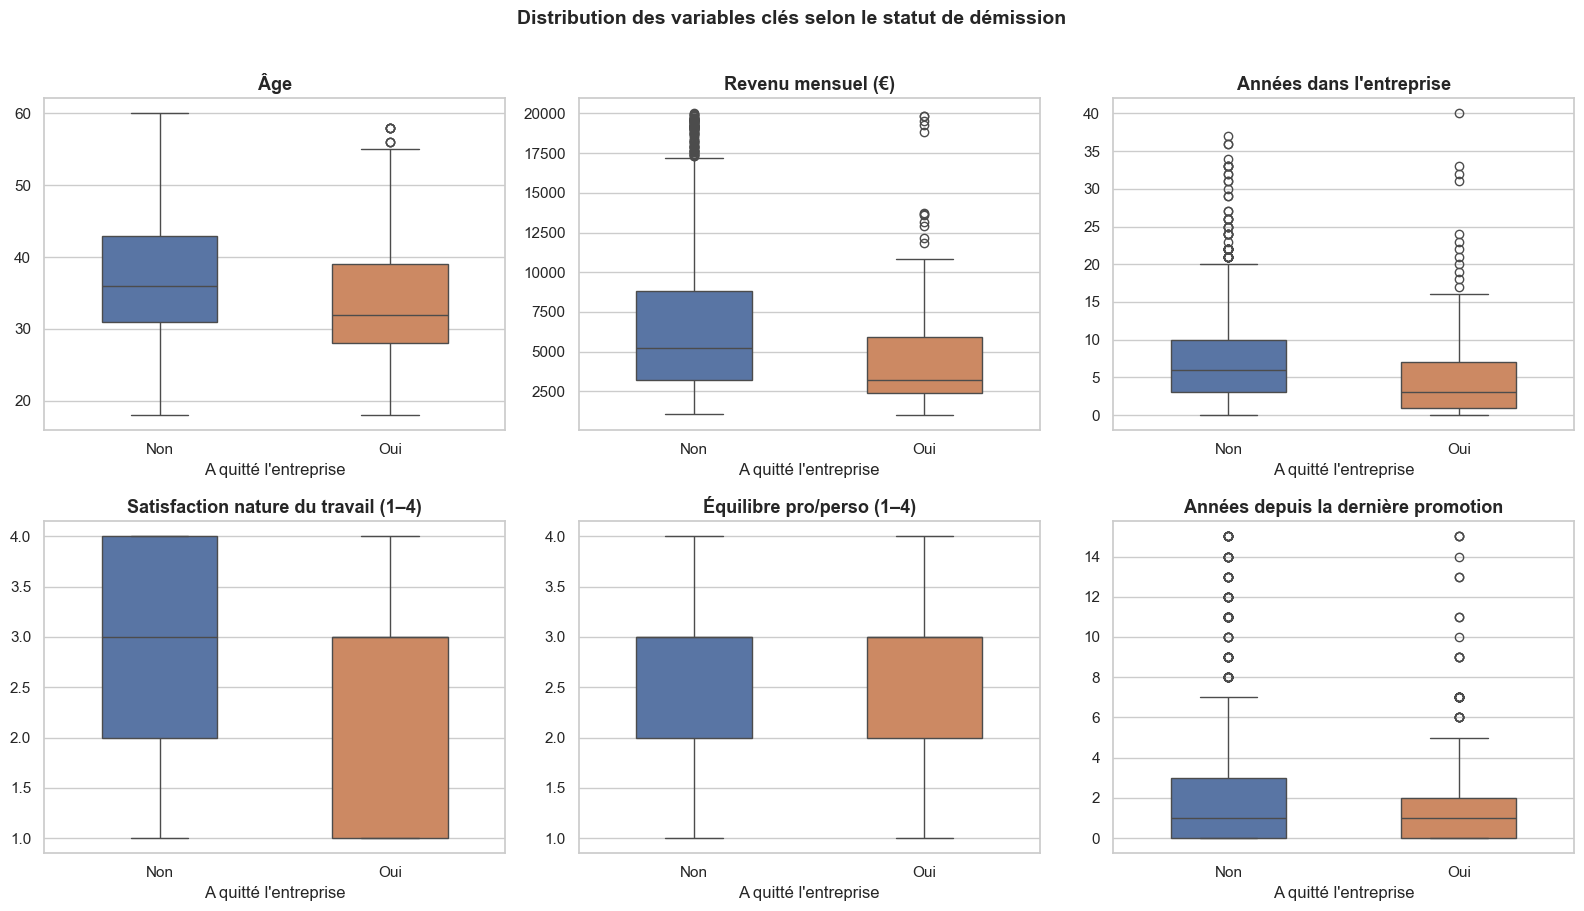

In [15]:
# Boxplots : 6 variables quantitatives clés
vars_box = [
    ('age',                                   'Âge'),
    ('revenu_mensuel',                         'Revenu mensuel (€)'),
    ('annees_dans_l_entreprise',               'Années dans l\'entreprise'),
    ('satisfaction_employee_nature_travail',   'Satisfaction nature du travail (1–4)'),
    ('satisfaction_employee_equilibre_pro_perso', 'Équilibre pro/perso (1–4)'),
    ('annees_depuis_la_derniere_promotion',    'Années depuis la dernière promotion'),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, (col, label) in enumerate(vars_box):
    sns.boxplot(
        data=df, x='a_quitte_l_entreprise', y=col,
        palette=PALETTE, order=['Non', 'Oui'], width=0.5, ax=axes[i]
    )
    axes[i].set_title(label)
    axes[i].set_xlabel('A quitté l\'entreprise')
    axes[i].set_ylabel('')

fig.suptitle('Distribution des variables clés selon le statut de démission',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/fig_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()


In [16]:
# Taux d'attrition par variable qualitative
def taux_attrition_par(col):
    return (
        df.groupby(col)['a_quitte_l_entreprise']
        .apply(lambda s: pd.Series({
            'effectif'  : len(s),
            'partis'    : (s == 'Oui').sum(),
            'taux_%'    : round((s == 'Oui').mean() * 100, 1)
        }))
        .unstack()
        .sort_values('taux_%', ascending=False)
    )

for col in ['departement', 'poste', 'heure_supplementaires',
            'statut_marital', 'frequence_deplacement']:
    print(f"\n── Attrition par {col} ──")
    display(taux_attrition_par(col))



── Attrition par departement ──


,effectif,partis,taux_%
departement,,,
Commercial,446.0,92.0,20.6
Ressources Humaines,63.0,12.0,19.0
Consulting,961.0,133.0,13.8



── Attrition par poste ──


,effectif,partis,taux_%
poste,,,
Représentant Commercial,83.0,33.0,39.8
Consultant,259.0,62.0,23.9
Ressources Humaines,52.0,12.0,23.1
Cadre Commercial,326.0,57.0,17.5
Assistant de Direction,292.0,47.0,16.1
Manager,131.0,9.0,6.9
Tech Lead,145.0,10.0,6.9
Senior Manager,102.0,5.0,4.9
Directeur Technique,80.0,2.0,2.5



── Attrition par heure_supplementaires ──


,effectif,partis,taux_%
heure_supplementaires,,,
Oui,416.0,127.0,30.5
Non,1054.0,110.0,10.4



── Attrition par statut_marital ──


,effectif,partis,taux_%
statut_marital,,,
Célibataire,470.0,120.0,25.5
Marié(e),673.0,84.0,12.5
Divorcé(e),327.0,33.0,10.1



── Attrition par frequence_deplacement ──


,effectif,partis,taux_%
frequence_deplacement,,,
Frequent,277.0,69.0,24.9
Occasionnel,1043.0,156.0,15.0
Aucun,150.0,12.0,8.0


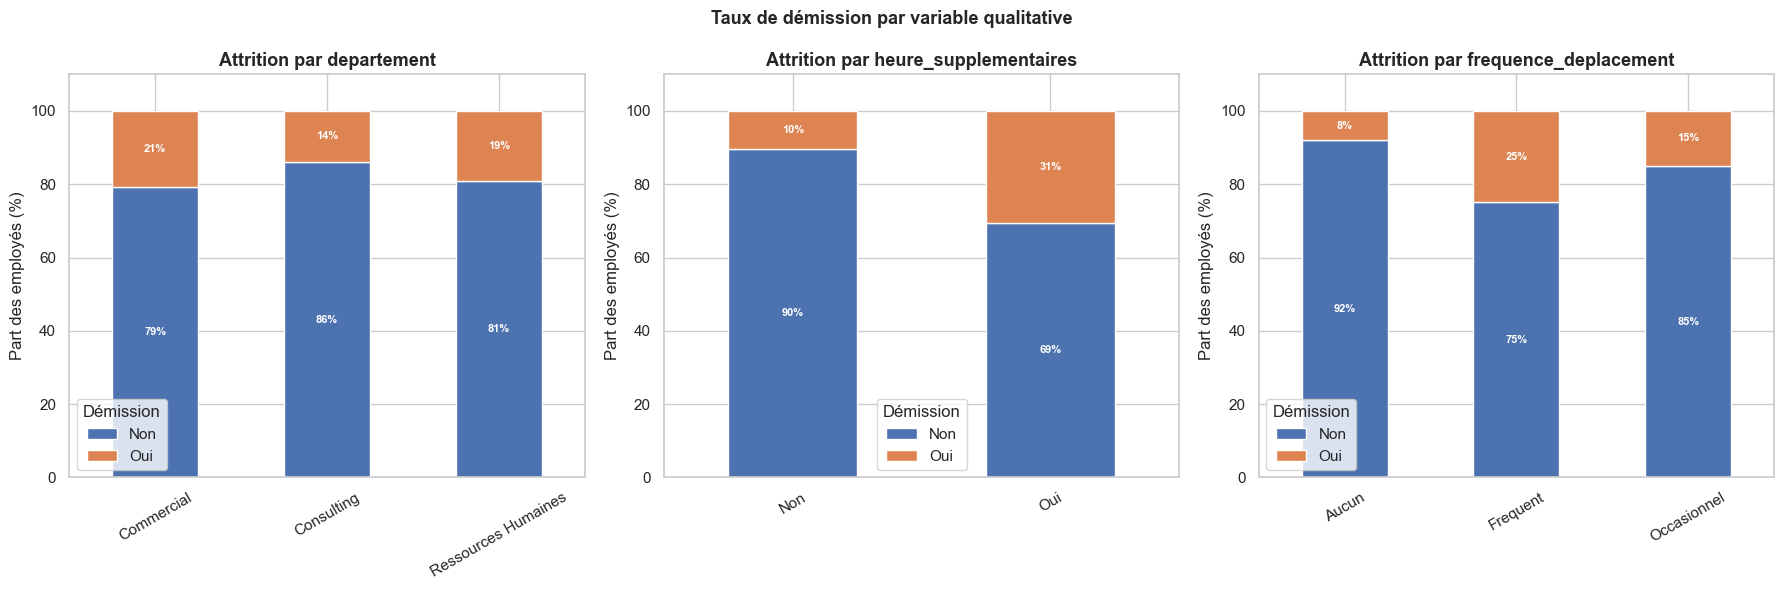

In [17]:
# Barres empilées : 3 variables qualitatives
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, col in zip(axes, ['departement', 'heure_supplementaires', 'frequence_deplacement']):
    ct = pd.crosstab(df[col], df['a_quitte_l_entreprise'], normalize='index') * 100
    ct[['Non', 'Oui']].plot(
        kind='bar', stacked=True, ax=ax,
        color=[PALETTE['Non'], PALETTE['Oui']],
        edgecolor='white'
    )
    ax.set_title(f'Attrition par {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Part des employés (%)')
    ax.set_ylim(0, 110)
    ax.tick_params(axis='x', rotation=30)
    ax.legend(title='Démission')
    for p in ax.patches:
        h = p.get_height()
        if h > 5:
            ax.text(p.get_x() + p.get_width() / 2, p.get_y() + h / 2,
                    f'{h:.0f}%', ha='center', va='center',
                    fontsize=8, color='white', fontweight='bold')

fig.suptitle('Taux de démission par variable qualitative', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_barres_quali.png', dpi=150, bbox_inches='tight')
plt.show()


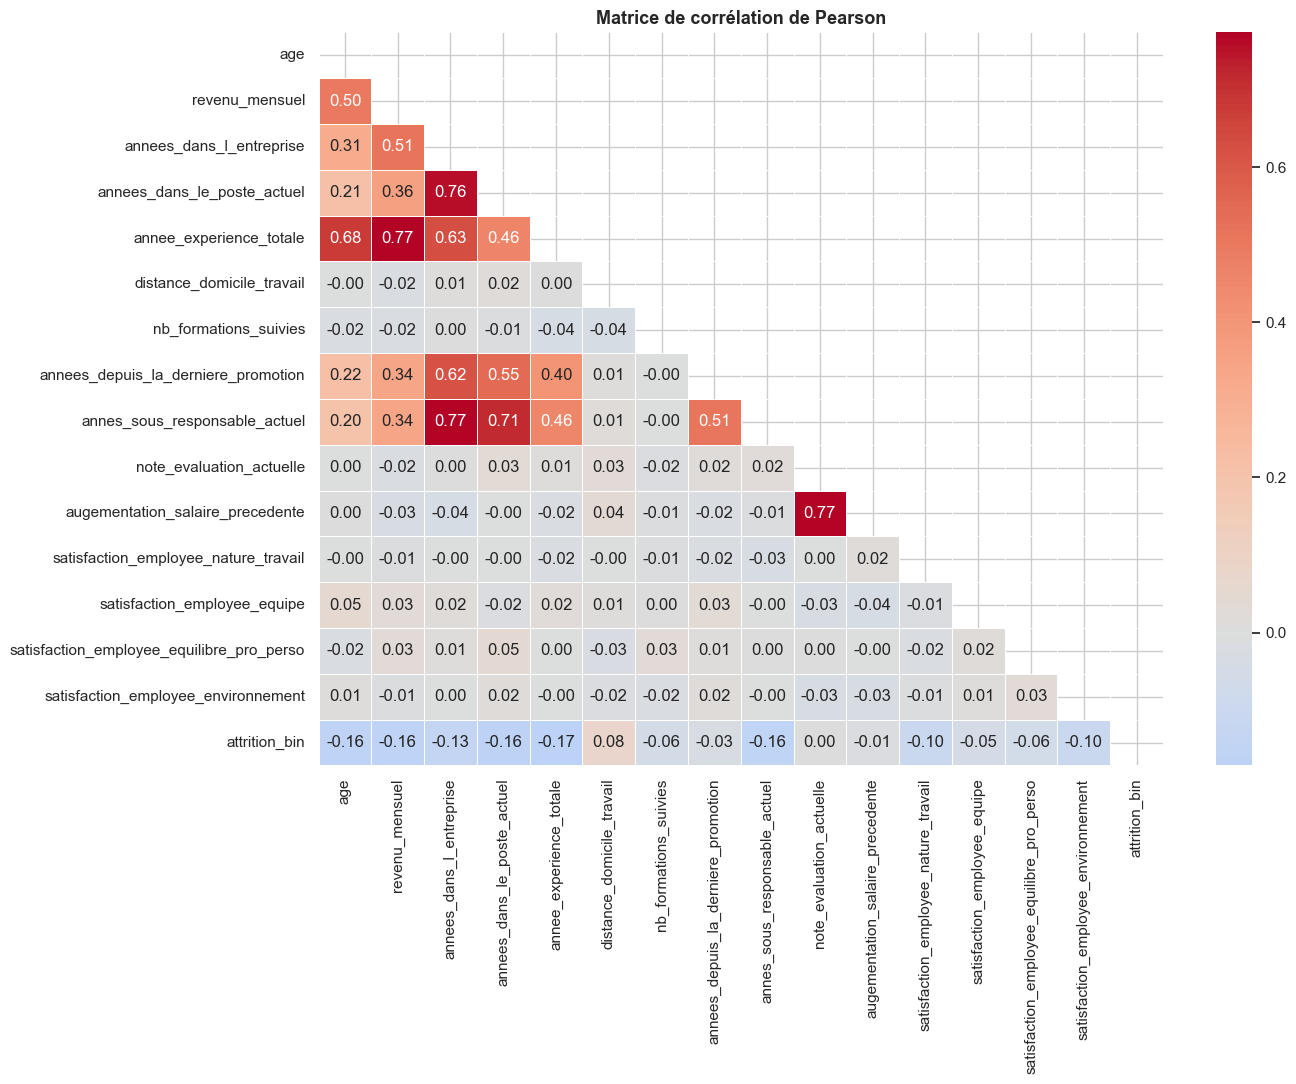

In [18]:
# Heatmap de corrélation de Pearson
df_corr = df[cols_quanti].copy()
df_corr['attrition_bin'] = (df['a_quitte_l_entreprise'] == 'Oui').astype(int)

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(df_corr.corr(), dtype=bool))
sns.heatmap(df_corr.corr(), mask=mask, cmap='coolwarm', center=0,
            annot=True, fmt='.2f', linewidths=0.4, ax=ax)
ax.set_title('Matrice de corrélation de Pearson', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_heatmap_pearson.png', dpi=150, bbox_inches='tight')
plt.show()


## Étape 3 — Feature Engineering & Préparation de X et y

### 3.1 Suppression des colonnes inutiles

Avant d'encoder, je retire les colonnes sans pouvoir discriminant :
- `id_employee` : identifiant technique, pas une feature  
- `nombre_heures_travailless` : valeur unique (80) pour tout le monde → aucune variance  


In [19]:
# Je crée une fonction pour isoler et reproduire facilement ces transformations
def preparer_features(df: pd.DataFrame):
    """
    Retourne X (features) et y (cible binaire 0/1).
    Peut être réutilisée sur tout nouveau jeu de données.
    """
    df_work = df.copy()

    # Suppression des colonnes non-features
    cols_a_supprimer = ['id_employee', 'nombre_heures_travailless', 'a_quitte_l_entreprise']
    df_work = df_work.drop(columns=cols_a_supprimer)

    # Variable cible
    y = (df['a_quitte_l_entreprise'] == 'Oui').astype(int)

    return df_work, y


X_raw, y = preparer_features(df)

print(f"X_raw : {X_raw.shape[0]} lignes × {X_raw.shape[1]} colonnes")
print(f"y     : {y.shape[0]} valeurs — taux d'attrition : {y.mean():.1%}")
print(f"\nColonnes de X :")
print(X_raw.columns.tolist())


X_raw : 1470 lignes × 28 colonnes
y     : 1470 valeurs — taux d'attrition : 16.1%

Colonnes de X :
['age', 'genre', 'revenu_mensuel', 'statut_marital', 'departement', 'poste', 'nombre_experiences_precedentes', 'annee_experience_totale', 'annees_dans_l_entreprise', 'annees_dans_le_poste_actuel', 'satisfaction_employee_environnement', 'note_evaluation_precedente', 'niveau_hierarchique_poste', 'satisfaction_employee_nature_travail', 'satisfaction_employee_equipe', 'satisfaction_employee_equilibre_pro_perso', 'note_evaluation_actuelle', 'heure_supplementaires', 'augementation_salaire_precedente', 'nombre_participation_pee', 'nb_formations_suivies', 'nombre_employee_sous_responsabilite', 'distance_domicile_travail', 'niveau_education', 'domaine_etude', 'frequence_deplacement', 'annees_depuis_la_derniere_promotion', 'annes_sous_responsable_actuel']


### 3.2 Identification des types de features

Je distingue :
- **Features numériques continues** : à standardiser  
- **Features qualitatives nominales** : à encoder avec `OneHotEncoder` (pas d'ordre naturel)  
- **Features qualitatives ordinales** : à encoder avec `OrdinalEncoder` (ordre naturel à respecter)


In [20]:
# Features numériques
features_num = [
    'age', 'revenu_mensuel', 'nombre_experiences_precedentes',
    'annee_experience_totale', 'annees_dans_l_entreprise',
    'annees_dans_le_poste_actuel', 'distance_domicile_travail',
    'nb_formations_suivies', 'nombre_participation_pee',
    'nombre_employee_sous_responsabilite', 'annees_depuis_la_derniere_promotion',
    'annes_sous_responsable_actuel', 'augementation_salaire_precedente',
    'note_evaluation_precedente', 'note_evaluation_actuelle',
]

# Features qualitatives nominales (pas d'ordre → OneHotEncoder)
features_cat_nominal = [
    'genre', 'statut_marital', 'departement', 'poste',
    'domaine_etude', 'heure_supplementaires', 'frequence_deplacement'
]

# Features qualitatives ordinales (ordre naturel → OrdinalEncoder)
# niveau_education : 1 < 2 < 3 < 4 < 5
# niveau_hierarchique_poste : 1 < 2 < 3 < 4 < 5
# satisfaction_* : 1 < 2 < 3 < 4
features_cat_ordinal = [
    'niveau_education', 'niveau_hierarchique_poste',
    'satisfaction_employee_environnement',
    'satisfaction_employee_nature_travail',
    'satisfaction_employee_equipe',
    'satisfaction_employee_equilibre_pro_perso',
]

print("Numériques     :", len(features_num))
print("Nominales (OHE):", len(features_cat_nominal))
print("Ordinales (Ord):", len(features_cat_ordinal))
print("Total          :", len(features_num) + len(features_cat_nominal) + len(features_cat_ordinal),
      "vs colonnes X :", X_raw.shape[1])


Numériques     : 15
Nominales (OHE): 7
Ordinales (Ord): 6
Total          : 28 vs colonnes X : 28


### 3.3 Construction du préprocesseur (ColumnTransformer)

In [21]:
# Ordres pour les features ordinales
ordres_ordinal = [
    [1, 2, 3, 4, 5],  # niveau_education
    [1, 2, 3, 4, 5],  # niveau_hierarchique_poste
    [1, 2, 3, 4],     # satisfaction_environnement
    [1, 2, 3, 4],     # satisfaction_nature_travail
    [1, 2, 3, 4],     # satisfaction_equipe
    [1, 2, 3, 4],     # satisfaction_equilibre
]

preprocesseur = ColumnTransformer(transformers=[
    ('num',     StandardScaler(),                                features_num),
    ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat_nominal),
    ('cat_ord', OrdinalEncoder(categories=ordres_ordinal),       features_cat_ordinal),
], remainder='drop')

### 3.4 Matrice de corrélation de Spearman (pour vérifier les corrélations non-linéaires)

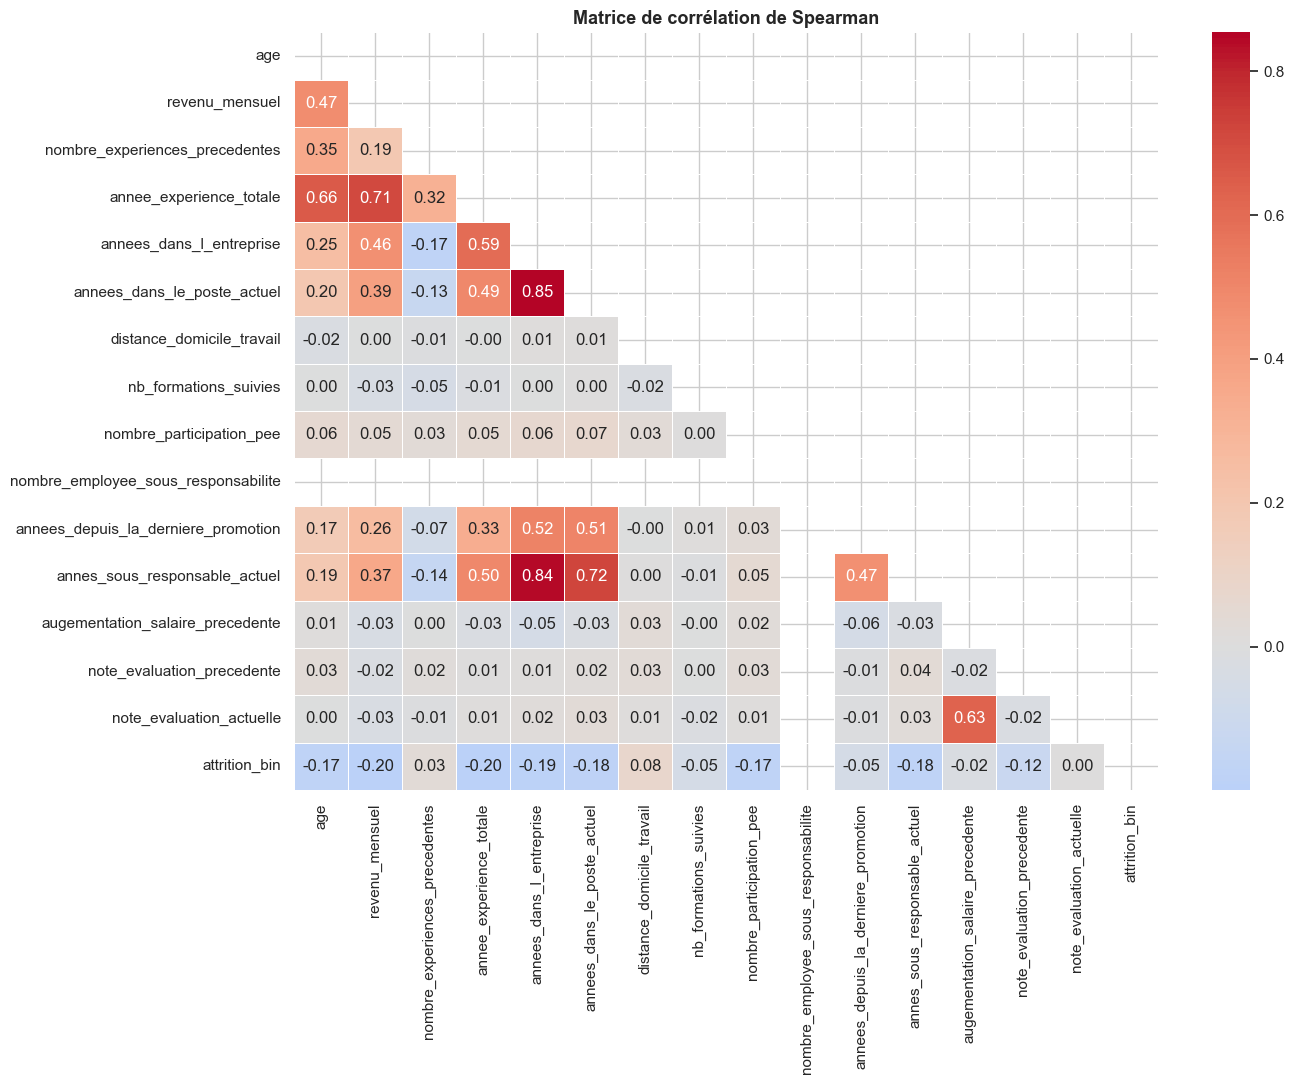

In [22]:
corr_spearman = df[features_num + ['a_quitte_l_entreprise']].copy()
corr_spearman['attrition_bin'] = (df['a_quitte_l_entreprise'] == 'Oui').astype(int)
corr_sp = corr_spearman[features_num + ['attrition_bin']].corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_sp, dtype=bool))
sns.heatmap(corr_sp, mask=mask, cmap='coolwarm', center=0,
            annot=True, fmt='.2f', linewidths=0.4, ax=ax)
ax.set_title('Matrice de corrélation de Spearman', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_heatmap_spearman.png', dpi=150, bbox_inches='tight')
plt.show()


> **Lecture :** Je recherche des valeurs > 0.8 ou < -0.8 entre deux features (hors attrition),
qui indiqueraient une redondance. Si c'est le cas, je supprime l'une des deux features.


## Étape 4 — Modélisation Baseline

Je commence par une séparation **train / test** simple, puis j'entraîne 3 modèles dans
l'ordre croissant de complexité : Dummy → Régression Logistique → Random Forest.

### 4.1 Séparation train / test (stratifiée)

La **stratification** garantit que les proportions d'attrition sont respectées dans les deux jeux.


In [23]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y,
    test_size=0.2,
    random_state=42,
    stratify=y       # ← important : je respecte le déséquilibre dans chaque split
)

print(f"Train : {X_train_raw.shape[0]} obs. — taux attrition : {y_train.mean():.1%}")
print(f"Test  : {X_test_raw.shape[0]} obs. — taux attrition : {y_test.mean():.1%}")


Train : 1176 obs. — taux attrition : 16.2%
Test  : 294 obs. — taux attrition : 16.0%


### 4.2 Fonction utilitaire d'évaluation

Je crée une fonction réutilisable pour afficher les métriques sur train ET test, et la matrice de confusion.

In [24]:
def evaluer_modele(modele, X_train, X_test, y_train, y_test, nom='Modèle'):
    """Affiche les métriques clés et la matrice de confusion."""
    # Prédictions
    y_pred_train = modele.predict(X_train)
    y_pred_test  = modele.predict(X_test)

    print(f"\n{'='*55}")
    print(f"  {nom}")
    print(f"{'='*55}")
    print("\n── TRAIN ──")
    print(classification_report(y_train, y_pred_train, target_names=['Non', 'Oui']))
    print("── TEST  ──")
    print(classification_report(y_test,  y_pred_test,  target_names=['Non', 'Oui']))

    # Matrice de confusion (test uniquement)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred_test,
        display_labels=['Non (resté)', 'Oui (parti)'],
        cmap='Blues', ax=ax
    )
    ax.set_title(f'Matrice de confusion — {nom} (Test)', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../reports/figures/fig_confusion_{nom.replace(" ", "_")}.png', dpi=150, bbox_inches='tight')
    plt.show()

    return {
        'nom'      : nom,
        'recall_test'   : recall_score(y_test, y_pred_test, zero_division=0),
        'precision_test': precision_score(y_test, y_pred_test, zero_division=0),
        'f1_test'       : f1_score(y_test, y_pred_test, zero_division=0),
    }

resultats_baseline = []


### 4.3 Modèle 1 — Dummy (référence)

Le modèle Dummy prédit toujours la classe majoritaire (Non). C'est mon étalon : tout modèle utile doit le surpasser.


  Dummy

── TRAIN ──
              precision    recall  f1-score   support

         Non       0.84      1.00      0.91       986
         Oui       0.00      0.00      0.00       190

    accuracy                           0.84      1176
   macro avg       0.42      0.50      0.46      1176
weighted avg       0.70      0.84      0.76      1176

── TEST  ──
              precision    recall  f1-score   support

         Non       0.84      1.00      0.91       247
         Oui       0.00      0.00      0.00        47

    accuracy                           0.84       294
   macro avg       0.42      0.50      0.46       294
weighted avg       0.71      0.84      0.77       294



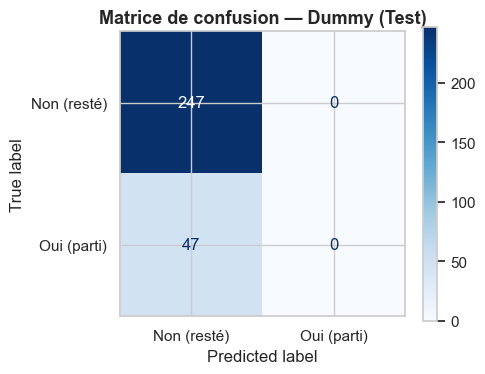

In [25]:
pipe_dummy = Pipeline([
    ('prep',   preprocesseur),
    ('modele', DummyClassifier(strategy='most_frequent', random_state=42))
])
pipe_dummy.fit(X_train_raw, y_train)
res = evaluer_modele(pipe_dummy, X_train_raw, X_test_raw, y_train, y_test, 'Dummy')
resultats_baseline.append(res)


> **Interprétation :** Le Dummy a un rappel (recall) de 0 sur la classe 'Oui' : il ne détecte
aucune démission. C'est le plancher à dépasser.


### 4.4 Modèle 2 — Régression Logistique (linéaire)

Un modèle linéaire simple pour tester si les séparations sont linéairement apprises.


  Régression Logistique

── TRAIN ──
              precision    recall  f1-score   support

         Non       0.91      0.98      0.94       986
         Oui       0.83      0.48      0.61       190

    accuracy                           0.90      1176
   macro avg       0.87      0.73      0.77      1176
weighted avg       0.89      0.90      0.89      1176

── TEST  ──
              precision    recall  f1-score   support

         Non       0.89      0.96      0.92       247
         Oui       0.61      0.36      0.45        47

    accuracy                           0.86       294
   macro avg       0.75      0.66      0.69       294
weighted avg       0.84      0.86      0.85       294



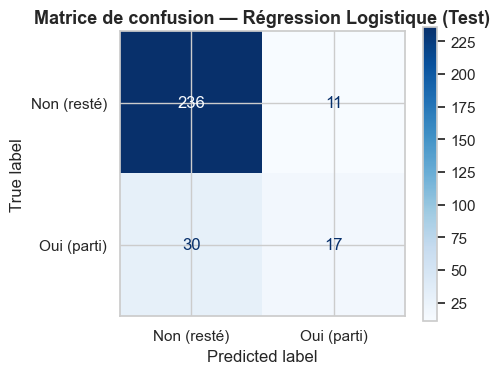

In [26]:
pipe_lr = Pipeline([
    ('prep',   preprocesseur),
    ('modele', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_lr.fit(X_train_raw, y_train)
res = evaluer_modele(pipe_lr, X_train_raw, X_test_raw, y_train, y_test, 'Régression Logistique')
resultats_baseline.append(res)


### 4.5 Modèle 3 — Random Forest (non-linéaire)


  Random Forest

── TRAIN ──
              precision    recall  f1-score   support

         Non       1.00      1.00      1.00       986
         Oui       1.00      1.00      1.00       190

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176

── TEST  ──
              precision    recall  f1-score   support

         Non       0.86      0.98      0.91       247
         Oui       0.54      0.15      0.23        47

    accuracy                           0.84       294
   macro avg       0.70      0.56      0.57       294
weighted avg       0.81      0.84      0.80       294



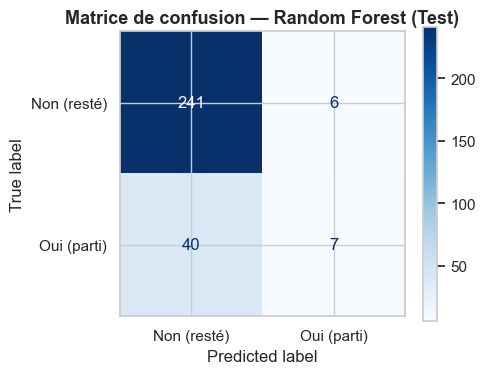

In [27]:
pipe_rf = Pipeline([
    ('prep',   preprocesseur),
    ('modele', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
pipe_rf.fit(X_train_raw, y_train)
res = evaluer_modele(pipe_rf, X_train_raw, X_test_raw, y_train, y_test, 'Random Forest')
resultats_baseline.append(res)


### 4.6 Comparaison des 3 modèles baseline

In [28]:
df_resultats = pd.DataFrame(resultats_baseline).set_index('nom').round(3)
display(df_resultats.style.highlight_max(axis=0, color='#d4edda'))


,recall_test,precision_test,f1_test
nom,,,
Dummy,0.000000,0.000000,0.000000
Régression Logistique,0.362000,0.607000,0.453000
Random Forest,0.149000,0.538000,0.233000


> **Interprétation :** Je compare les scores sur le jeu de **test** uniquement.
> - Le **recall** mesure ma capacité à détecter les vrais démissionnaires.  
> - La **precision** mesure combien de mes alertes sont de vraies démissions.  
> - En RH, **rater un démissionnaire (faux négatif) est plus coûteux** que de déclencher une action préventive inutile → je prioriserai le recall.


## Étape 5 — Modélisation avancée, Fine-tuning & Interprétabilité SHAP

### 5.1 Stratégie améliorée

Je mets en place 4 améliorations par rapport à la baseline :

1. **Validation croisée stratifiée** (StratifiedKFold) pour mesurer la stabilité des performances  
2. **Gestion du déséquilibre** via `class_weight='balanced'` dans le Random Forest  
3. **Comparaison avec SMOTE** — une alternative de rééchantillonnage pour gérer le déséquilibre  
4. **Fine-tuning** des hyperparamètres avec `RandomizedSearchCV` sur la meilleure stratégie

In [29]:
# Validation croisée avec Random Forest pondéré
rf_balanced = RandomForestClassifier(
    class_weight='balanced',   # ← le modèle pèse davantage les démissionnaires
    random_state=42,
    n_jobs=-1
)

pipe_rf_bal = Pipeline([
    ('prep',   preprocesseur),
    ('modele', rf_balanced)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Je stocke les métriques de chaque fold pour calculer moyenne + écart-type
scores = cross_validate(
    pipe_rf_bal, X_raw, y,
    cv=cv,
    scoring=['recall', 'precision', 'f1'],
    return_train_score=True,
    n_jobs=-1
)

print("Résultats en validation croisée (5 folds) — RF avec class_weight='balanced'")
for metric in ['recall', 'precision', 'f1']:
    train_m = scores[f'train_{metric}']
    test_m  = scores[f'test_{metric}']
    print(f"  {metric:12s} | Train: {train_m.mean():.3f} ± {train_m.std():.3f}"
          f"  | Test: {test_m.mean():.3f} ± {test_m.std():.3f}")


Résultats en validation croisée (5 folds) — RF avec class_weight='balanced'
  recall       | Train: 1.000 ± 0.000  | Test: 0.177 ± 0.042
  precision    | Train: 1.000 ± 0.000  | Test: 0.804 ± 0.100
  f1           | Train: 1.000 ± 0.000  | Test: 0.287 ± 0.058


### 5.1b Stratégie alternative — SMOTE

SMOTE (*Synthetic Minority Over-sampling Technique*) génère de nouveaux exemples de démissionnaires


In [30]:
pipe_smote = ImbPipeline([
    ('prep',   preprocesseur),
    ('smote',  SMOTE(random_state=42, k_neighbors=5)),
    ('modele', RandomForestClassifier(
        # Pas de class_weight ici : SMOTE gere deja le desequilibre
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Apercu de ce que SMOTE produit (applique manuellement sur le train uniquement pour visualiser)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

prep_tmp = ColumnTransformer(transformers=preprocesseur.transformers, remainder='drop').fit(X_train_raw)
X_train_t_tmp = prep_tmp.transform(X_train_raw)

smote_tmp = SMOTE(random_state=42)
X_res_tmp, y_res_tmp = smote_tmp.fit_resample(X_train_t_tmp, y_train)

poids = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)

print('── class_weight balanced ──')
print(f'  Poids classe 0 (Non) : {poids[0]:.3f}')
print(f'  Poids classe 1 (Oui) : {poids[1]:.3f}  (ratio Oui/Non : {poids[1]/poids[0]:.1f}x)')
print()
print('── SMOTE ──')
print(f'  Avant : {X_train_t_tmp.shape[0]} obs. | Oui: {y_train.sum()} ({y_train.mean():.1%})')
print(f'  Apres : {X_res_tmp.shape[0]} obs. | Oui: {y_res_tmp.sum()} ({y_res_tmp.mean():.1%})')
print(f'  Exemples synthetiques crees : {X_res_tmp.shape[0] - X_train_t_tmp.shape[0]}')


── class_weight balanced ──
  Poids classe 0 (Non) : 0.596
  Poids classe 1 (Oui) : 3.095  (ratio Oui/Non : 5.2x)

── SMOTE ──
  Avant : 1176 obs. | Oui: 190 (16.2%)
  Apres : 1972 obs. | Oui: 986 (50.0%)
  Exemples synthetiques crees : 796


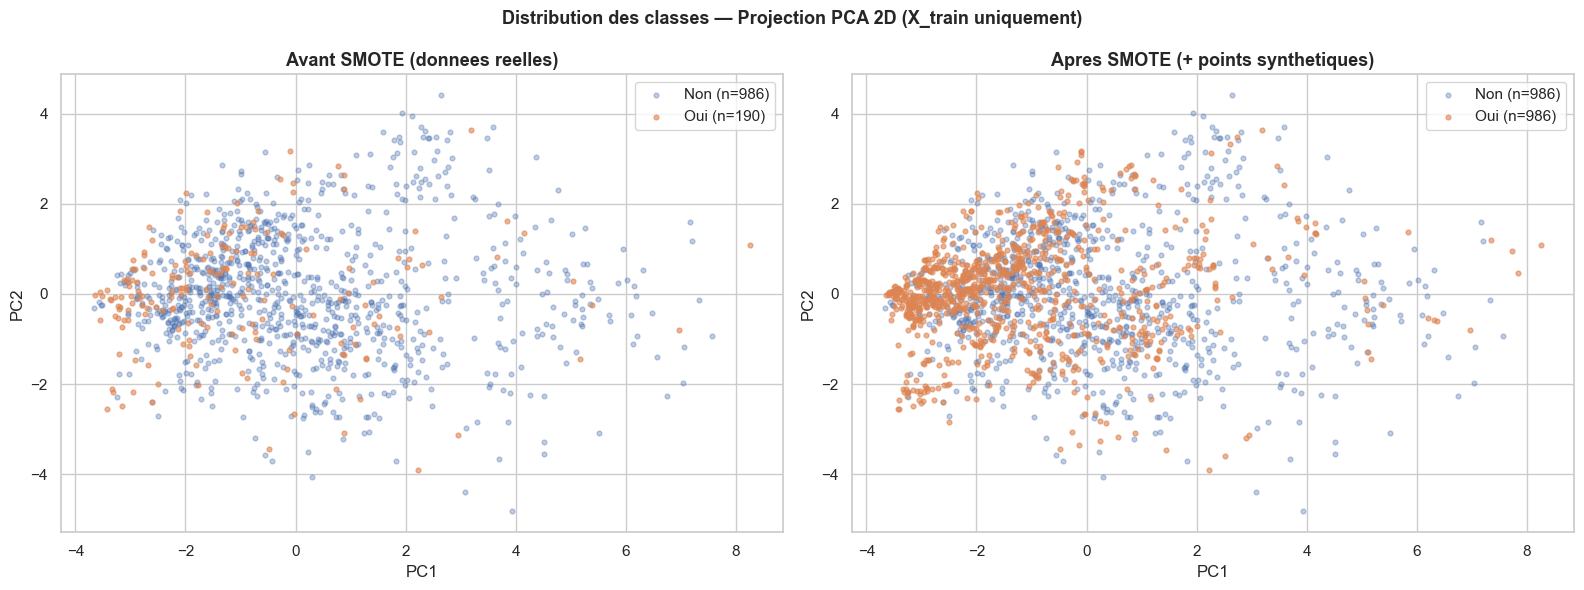

Variance expliquee : PC1=19.7%, PC2=7.7%


In [31]:
# ── Visualisation PCA 2D : distribution avant / apres SMOTE ───
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca_avant = pca.fit_transform(X_train_t_tmp)
X_pca_apres = pca.transform(X_res_tmp)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, X_pca, y_pca, titre in [
    (axes[0], X_pca_avant, y_train.values, 'Avant SMOTE (donnees reelles)'),
    (axes[1], X_pca_apres, y_res_tmp,      'Apres SMOTE (+ points synthetiques)'),
]:
    idx_0 = y_pca == 0
    idx_1 = y_pca == 1
    ax.scatter(X_pca[idx_0, 0], X_pca[idx_0, 1],
               c=PALETTE['Non'], alpha=0.35, s=12, label=f'Non (n={idx_0.sum()})')
    ax.scatter(X_pca[idx_1, 0], X_pca[idx_1, 1],
               c=PALETTE['Oui'], alpha=0.6, s=12, label=f'Oui (n={idx_1.sum()})')
    ax.set_title(titre)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend()

fig.suptitle('Distribution des classes — Projection PCA 2D (X_train uniquement)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_pca_smote.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Variance expliquee : PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}')


In [32]:
# ── Validation croisee — SMOTE ──

scores_smote = cross_validate(
    pipe_smote, X_raw, y,
    cv=cv,
    scoring=['recall', 'precision', 'f1'],
    return_train_score=True,
    n_jobs=-1
)

print("Resultats en validation croisee (5 folds) — RF avec SMOTE")
for metric in ['recall', 'precision', 'f1']:
    train_m = scores_smote[f'train_{metric}']
    test_m  = scores_smote[f'test_{metric}']
    print(f"  {metric:12s} | Train: {train_m.mean():.3f} +/- {train_m.std():.3f}"
          f"  | Test: {test_m.mean():.3f} +/- {test_m.std():.3f}")


Resultats en validation croisee (5 folds) — RF avec SMOTE
  recall       | Train: 1.000 +/- 0.000  | Test: 0.329 +/- 0.051
  precision    | Train: 1.000 +/- 0.000  | Test: 0.647 +/- 0.147
  f1           | Train: 1.000 +/- 0.000  | Test: 0.434 +/- 0.072


### 5.1c Comparaison directe — `class_weight='balanced'` vs SMOTE

Je compare maintenant les deux stratégies sur les mêmes métriques et le même protocole de CV.


In [33]:
# ── Tableau comparatif des resultats en CV ──
lignes_comp = []
for nom, sc in [('class_weight balanced', scores), ('SMOTE', scores_smote)]:
    lignes_comp.append({
        'Strategie'          : nom,
        'Recall Train'       : f"{sc['train_recall'].mean():.3f} +/- {sc['train_recall'].std():.3f}",
        'Recall Test (moy)'  : sc['test_recall'].mean(),
        'Recall Test (std)'  : sc['test_recall'].std(),
        'Precision Test'     : sc['test_precision'].mean(),
        'F1 Test'            : sc['test_f1'].mean(),
    })

df_comp_cv = pd.DataFrame(lignes_comp).set_index('Strategie').round(3)
display(
    df_comp_cv.style
    .highlight_max(axis=0, subset=['Recall Test (moy)', 'Precision Test', 'F1 Test'], color='#d4edda')
    .highlight_min(axis=0, subset=['Recall Test (std)'], color='#d4edda')
)
print('Vert = meilleure valeur | Pour std : vert = plus faible (plus stable)')


,Recall Train,Recall Test (moy),Recall Test (std),Precision Test,F1 Test
Strategie,,,,,
class_weight balanced,1.000 +/- 0.000,0.177000,0.042000,0.804000,0.287000
SMOTE,1.000 +/- 0.000,0.329000,0.051000,0.647000,0.434000


Vert = meilleure valeur | Pour std : vert = plus faible (plus stable)


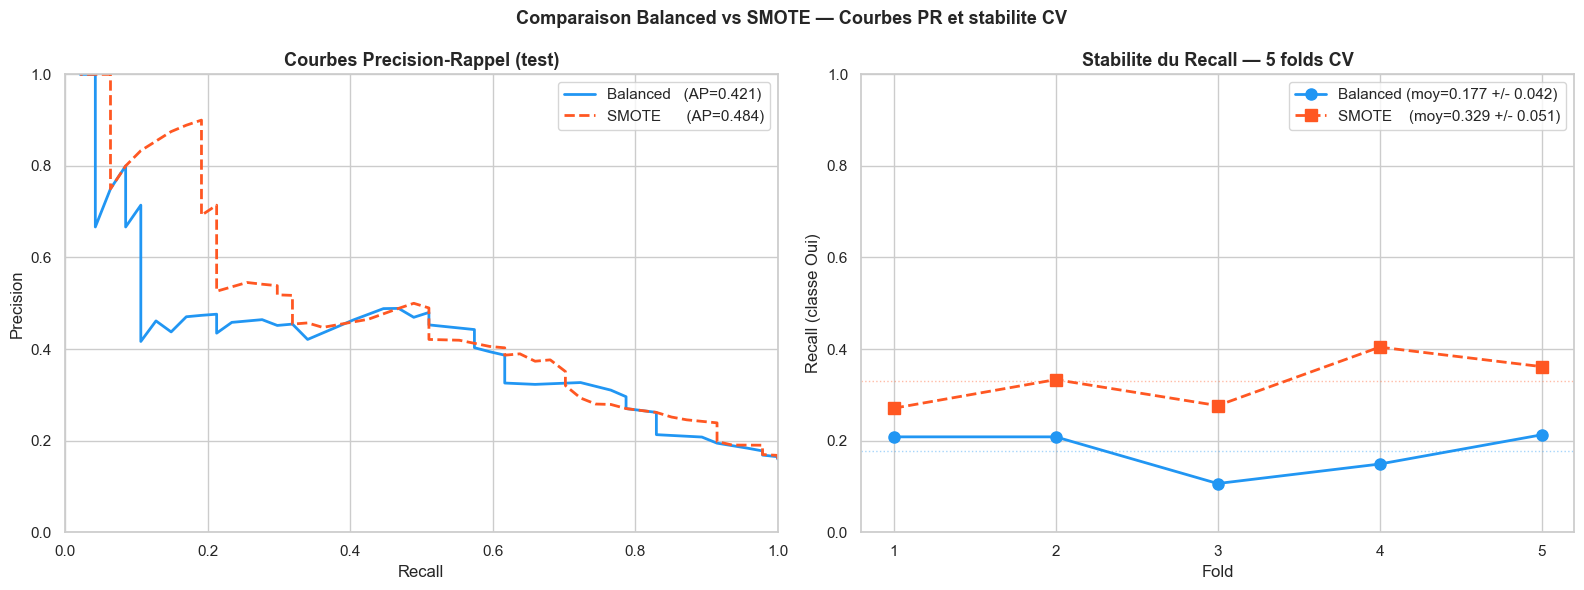

In [34]:
# Courbes PR superposees + Stabilite fold par fold 

pipe_rf_bal.fit(X_train_raw, y_train)
pipe_smote.fit(X_train_raw, y_train)

y_proba_bal = pipe_rf_bal.predict_proba(X_test_raw)[:, 1]
y_proba_smo = pipe_smote.predict_proba(X_test_raw)[:, 1]

from sklearn.metrics import precision_recall_curve, average_precision_score

prec_bal, rec_bal, seuils_bal = precision_recall_curve(y_test, y_proba_bal)
prec_smo, rec_smo, seuils_smo = precision_recall_curve(y_test, y_proba_smo)
ap_bal = average_precision_score(y_test, y_proba_bal)
ap_smo = average_precision_score(y_test, y_proba_smo)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ax.plot(rec_bal[:-1], prec_bal[:-1], color='#2196F3', lw=2,
        label=f'Balanced   (AP={ap_bal:.3f})')
ax.plot(rec_smo[:-1], prec_smo[:-1], color='#FF5722', lw=2, linestyle='--',
        label=f'SMOTE      (AP={ap_smo:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Courbes Precision-Rappel (test)')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

folds = np.arange(1, 6)
r_bal_folds = scores['test_recall']
r_smo_folds = scores_smote['test_recall']

ax2 = axes[1]
ax2.plot(folds, r_bal_folds, 'o-', color='#2196F3', lw=2, ms=8,
         label=f'Balanced (moy={r_bal_folds.mean():.3f} +/- {r_bal_folds.std():.3f})')
ax2.plot(folds, r_smo_folds, 's--', color='#FF5722', lw=2, ms=8,
         label=f'SMOTE    (moy={r_smo_folds.mean():.3f} +/- {r_smo_folds.std():.3f})')
ax2.axhline(r_bal_folds.mean(), color='#2196F3', lw=1, alpha=0.4, linestyle=':')
ax2.axhline(r_smo_folds.mean(), color='#FF5722', lw=1, alpha=0.4, linestyle=':')
ax2.set_xlabel('Fold')
ax2.set_ylabel('Recall (classe Oui)')
ax2.set_title('Stabilite du Recall — 5 folds CV')
ax2.set_xticks(folds)
ax2.set_ylim(0, 1)
ax2.legend()

fig.suptitle('Comparaison Balanced vs SMOTE — Courbes PR et stabilite CV',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_comparaison_balanced_smote.png', dpi=150, bbox_inches='tight')
plt.show()


Seuil optimal Balanced : 0.24
Seuil optimal SMOTE    : 0.35



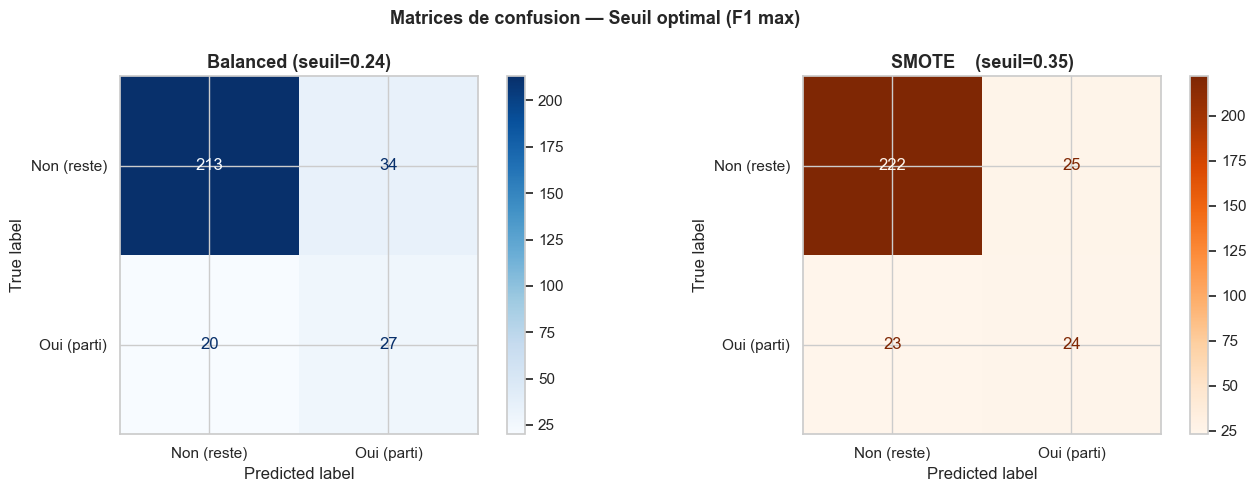

── Analyse des erreurs critiques (Faux Negatifs = demissionnaires rates) ──
  Balanced   | VP= 27  FN= 20  FP= 34  VN=213 | Demissionnaires rates : 20
  SMOTE      | VP= 24  FN= 23  FP= 25  VN=222 | Demissionnaires rates : 23


In [35]:
# ── Matrices de confusion cote a cote — seuil optimal pour chaque strategie ─────

f1_vals_bal = 2 * prec_bal[:-1] * rec_bal[:-1] / (prec_bal[:-1] + rec_bal[:-1] + 1e-9)
f1_vals_smo = 2 * prec_smo[:-1] * rec_smo[:-1] / (prec_smo[:-1] + rec_smo[:-1] + 1e-9)
seuil_bal_opt = seuils_bal[np.argmax(f1_vals_bal)]
seuil_smo_opt = seuils_smo[np.argmax(f1_vals_smo)]

y_pred_bal_opt = (y_proba_bal >= seuil_bal_opt).astype(int)
y_pred_smo_opt = (y_proba_smo >= seuil_smo_opt).astype(int)

print(f'Seuil optimal Balanced : {seuil_bal_opt:.2f}')
print(f'Seuil optimal SMOTE    : {seuil_smo_opt:.2f}')
print()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, y_pred, titre, cmap in [
    (axes[0], y_pred_bal_opt, f'Balanced (seuil={seuil_bal_opt:.2f})', 'Blues'),
    (axes[1], y_pred_smo_opt, f'SMOTE    (seuil={seuil_smo_opt:.2f})', 'Oranges'),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['Non (reste)', 'Oui (parti)'],
        cmap=cmap, ax=ax
    )
    ax.set_title(titre)

fig.suptitle('Matrices de confusion — Seuil optimal (F1 max)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_confusion_comparaison.png', dpi=150, bbox_inches='tight')
plt.show()

from sklearn.metrics import confusion_matrix as cm_fn
print('── Analyse des erreurs critiques (Faux Negatifs = demissionnaires rates) ──')
for nom, y_pred in [('Balanced', y_pred_bal_opt), ('SMOTE', y_pred_smo_opt)]:
    mat = cm_fn(y_test, y_pred)
    vn, fp, fn, vp = mat.ravel()
    print(f'  {nom:10s} | VP={vp:3d}  FN={fn:3d}  FP={fp:3d}  VN={vn:3d} | Demissionnaires rates : {fn}')


### 5.2 Courbe Précision-Rappel

Je cherche le **seuil optimal** de décision pour maximiser le recall sans trop sacrifier la précision.

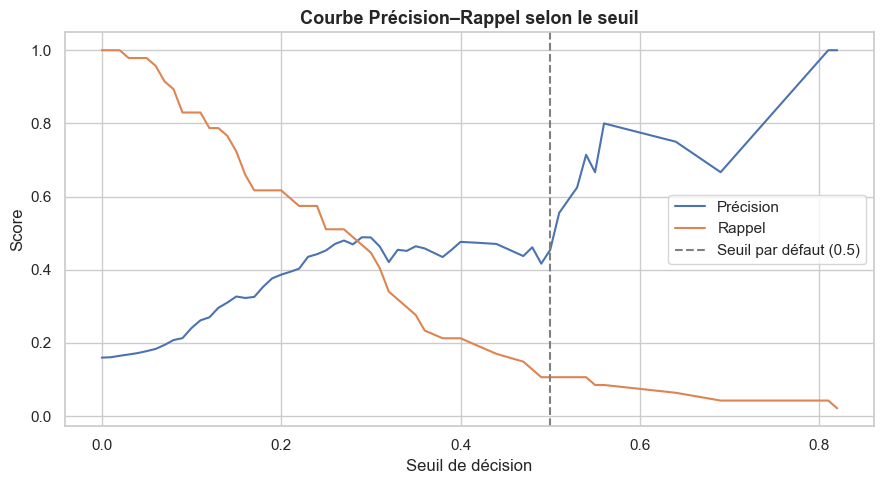

Seuil optimal (F1 max) : 0.24


In [36]:
# J'entraîne sur tout le train pour obtenir les probabilités sur le test
pipe_rf_bal.fit(X_train_raw, y_train)
y_proba = pipe_rf_bal.predict_proba(X_test_raw)[:, 1]  # proba d'être 'Oui'

precision_vals, recall_vals, seuils = precision_recall_curve(y_test, y_proba)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(seuils, precision_vals[:-1], label='Précision', color='#4C72B0')
ax.plot(seuils, recall_vals[:-1],   label='Rappel',    color='#DD8452')
ax.axvline(0.5, color='grey', linestyle='--', label='Seuil par défaut (0.5)')
ax.set_xlabel('Seuil de décision')
ax.set_ylabel('Score')
ax.set_title('Courbe Précision–Rappel selon le seuil', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/fig_precision_rappel.png', dpi=150, bbox_inches='tight')
plt.show()

# Je choisis le seuil qui maximise le F1
f1_par_seuil = 2 * precision_vals[:-1] * recall_vals[:-1] / (precision_vals[:-1] + recall_vals[:-1] + 1e-9)
seuil_optimal = seuils[np.argmax(f1_par_seuil)]
print(f"Seuil optimal (F1 max) : {seuil_optimal:.2f}")


In [37]:
# Évaluation avec le seuil optimal
y_pred_seuil = (y_proba >= seuil_optimal).astype(int)
print(f"Résultats avec le seuil optimal ({seuil_optimal:.2f}) :")
print(classification_report(y_test, y_pred_seuil, target_names=['Non', 'Oui']))


Résultats avec le seuil optimal (0.24) :
              precision    recall  f1-score   support

         Non       0.91      0.86      0.89       247
         Oui       0.44      0.57      0.50        47

    accuracy                           0.82       294
   macro avg       0.68      0.72      0.69       294
weighted avg       0.84      0.82      0.83       294



### 5.3 Fine-tuning — Recherche d'hyperparamètres

J'utilise `RandomizedSearchCV` (plus rapide qu'une grille exhaustive) pour trouver les meilleurs hyperparamètres.

In [38]:
param_grid = {
    'modele__n_estimators'      : [100, 200, 300],
    'modele__max_depth'         : [None, 5, 10, 15],
    'modele__min_samples_split' : [2, 5, 10],
    'modele__min_samples_leaf'  : [1, 2, 4],
    'modele__max_features'      : ['sqrt', 'log2'],
}

recherche = RandomizedSearchCV(
    pipe_rf_bal,
    param_distributions=param_grid,
    n_iter=20,           # je teste 20 combinaisons aléatoires
    cv=cv,
    scoring='recall',    # j'optimise le recall (priorité RH)
    n_jobs=-1,
    random_state=42,
    verbose=1
)
recherche.fit(X_train_raw, y_train)

print(f"\nMeilleurs paramètres : {recherche.best_params_}")
print(f"Meilleur recall (CV) : {recherche.best_score_:.3f}")


Fitting 5 folds for each of 20 candidates, totalling 100 fits

Meilleurs paramètres : {'modele__n_estimators': 200, 'modele__min_samples_split': 2, 'modele__min_samples_leaf': 4, 'modele__max_features': 'sqrt', 'modele__max_depth': 5}
Meilleur recall (CV) : 0.479



  RF Fine-tuné

── TRAIN ──
              precision    recall  f1-score   support

         Non       0.94      0.92      0.93       986
         Oui       0.64      0.72      0.67       190

    accuracy                           0.89      1176
   macro avg       0.79      0.82      0.80      1176
weighted avg       0.89      0.89      0.89      1176

── TEST  ──
              precision    recall  f1-score   support

         Non       0.91      0.87      0.89       247
         Oui       0.45      0.55      0.50        47

    accuracy                           0.82       294
   macro avg       0.68      0.71      0.69       294
weighted avg       0.84      0.82      0.83       294



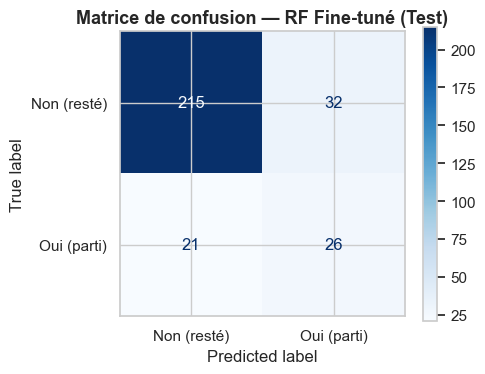

In [39]:
# Évaluation du meilleur modèle
meilleur_modele = recherche.best_estimator_
res_final = evaluer_modele(
    meilleur_modele,
    X_train_raw, X_test_raw,
    y_train, y_test,
    'RF Fine-tuné'
)


### 5.4 Interprétabilité — Feature Importance Globale

J'utilise **3 méthodes** que je compare pour identifier les variables les plus importantes :

1. **Feature Importance native** du Random Forest (basée sur la réduction d'impureté)  
2. **Permutation Importance** (sklearn) — plus robuste, mesure la perte de performance si on mélange une feature  
3. **SHAP Beeswarm Plot** — la méthode la plus fiable et interprétable


In [40]:
# Je récupère le modèle RF entraîné et les données transformées
rf_final    = meilleur_modele.named_steps['modele']
prep_final  = meilleur_modele.named_steps['prep']

X_train_t = prep_final.transform(X_train_raw)
X_test_t  = prep_final.transform(X_test_raw)

# Noms des features après transformation
noms_ohe = prep_final.named_transformers_['cat_ohe'].get_feature_names_out(features_cat_nominal)
noms_features = features_num + list(noms_ohe) + features_cat_ordinal


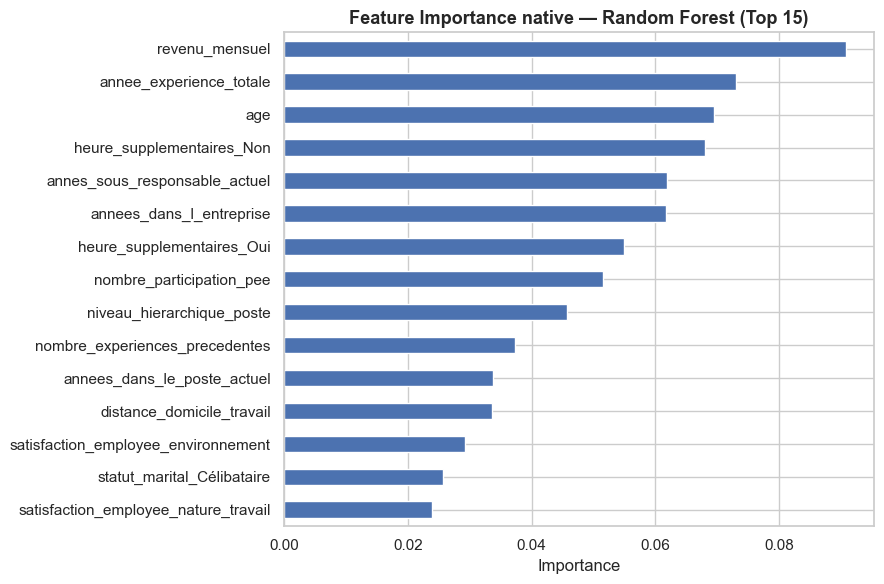

In [41]:
# ── Méthode 1 : Feature Importance native RF ───
importances_native = pd.Series(rf_final.feature_importances_, index=noms_features)
top15_native = importances_native.nlargest(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
top15_native.plot(kind='barh', ax=ax, color='#4C72B0', edgecolor='white')
ax.set_title('Feature Importance native — Random Forest (Top 15)', fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('../reports/figures/fig_importance_native.png', dpi=150, bbox_inches='tight')
plt.show()


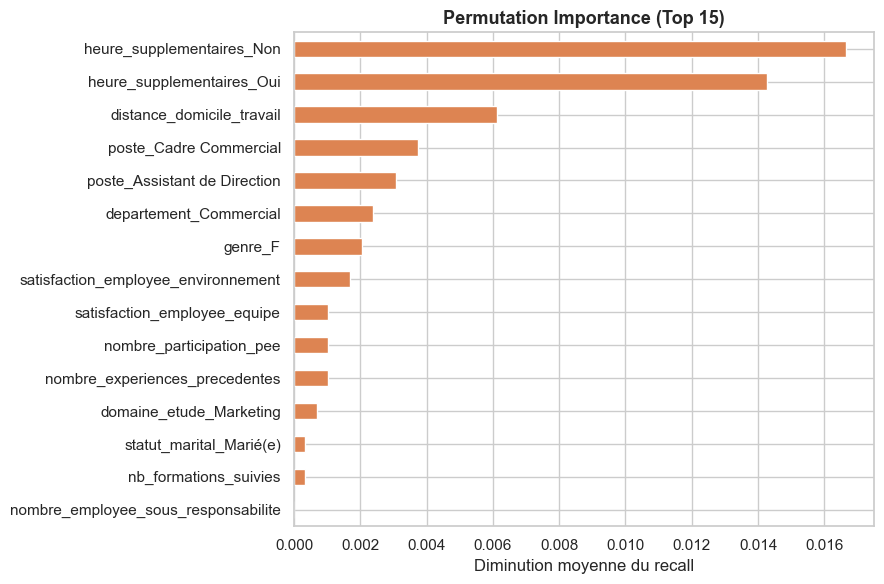

In [42]:
# ── Méthode 2 : Permutation Importance ──
from sklearn.inspection import permutation_importance

perm_imp = permutation_importance(
    rf_final, X_test_t, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)
perm_series = pd.Series(perm_imp.importances_mean, index=noms_features)
top15_perm  = perm_series.nlargest(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
top15_perm.plot(kind='barh', ax=ax, color='#DD8452', edgecolor='white')
ax.set_title('Permutation Importance (Top 15)', fontweight='bold')
ax.set_xlabel('Diminution moyenne du recall')
plt.tight_layout()
plt.savefig('../reports/figures/fig_importance_permutation.png', dpi=150, bbox_inches='tight')
plt.show()


Format shap_values : <class 'numpy.ndarray'>
Shape shap_oui     : (294, 49)
Shape X_test_t     : (294, 49)
Cohérence          : ✓ OK


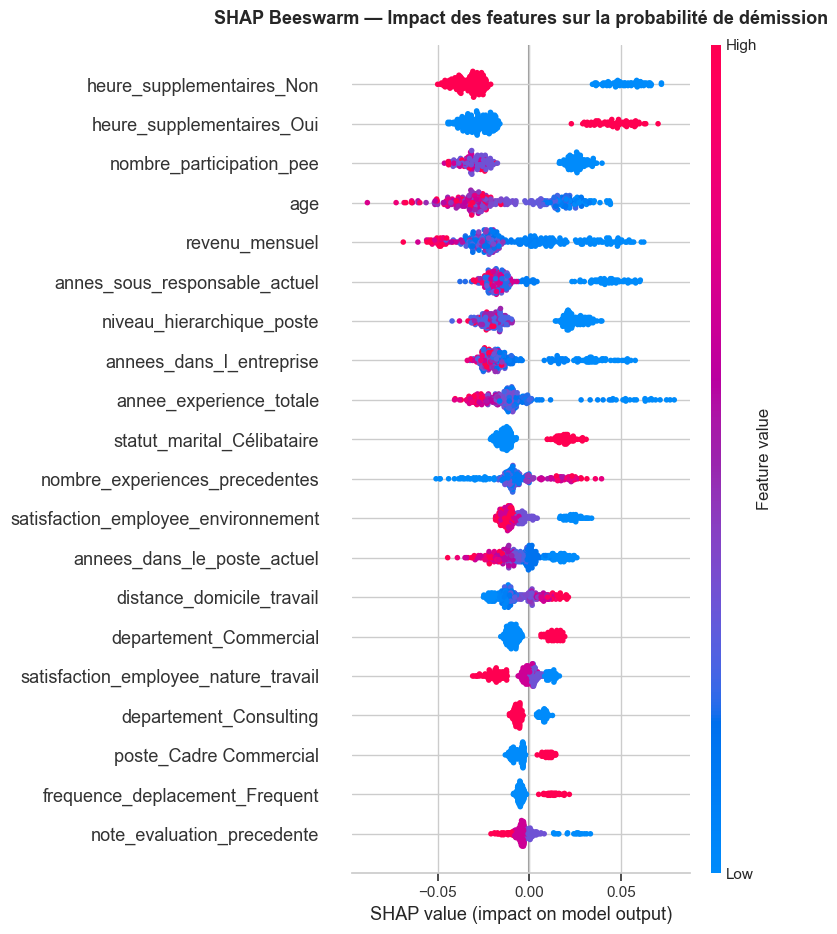

In [43]:
# ── Méthode 3 : SHAP — Feature Importance Globale (Beeswarm) ───
explainer   = shap.TreeExplainer(rf_final)
shap_values = explainer.shap_values(X_test_t)


if isinstance(shap_values, list):
    shap_oui = shap_values[1]
else:
    shap_oui = shap_values[:, :, 1]

# expected_value : même logique selon la version
if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_value = explainer.expected_value[1]
else:
    base_value = explainer.expected_value

print(f'Format shap_values : {type(shap_values)}')
print(f'Shape shap_oui     : {shap_oui.shape}')
print(f'Shape X_test_t     : {X_test_t.shape}')
print(f'Cohérence          : {"✓ OK" if shap_oui.shape == X_test_t.shape else "✗ Problème"}')

# Beeswarm plot : chaque point = un employé, couleur = valeur de la feature
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_oui, X_test_t,
    feature_names=noms_features,
    show=False
)
plt.title('SHAP Beeswarm — Impact des features sur la probabilité de démission',
          fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../reports/figures/fig_shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()


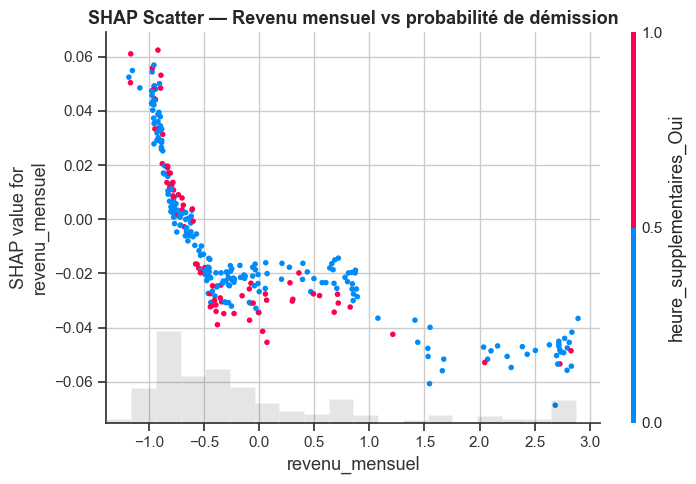

In [44]:
# ── SHAP Scatter : comprendre le sens d'une feature ─────

shap_exp = shap.Explanation(
    values       = shap_oui,
    base_values  = np.full(len(shap_oui), base_value),
    data         = X_test_t,
    feature_names= noms_features
)

shap.plots.scatter(
    shap_exp[:, 'revenu_mensuel'],
    color=shap_exp[:, 'heure_supplementaires_Oui'],
    show=False
)
plt.title('SHAP Scatter — Revenu mensuel vs probabilité de démission', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_shap_scatter.png', dpi=150, bbox_inches='tight')
plt.show()


### 5.5 Interprétabilité Locale — Waterfall Plot

Je choisis quelques employés spécifiques pour comprendre **pourquoi le modèle les a classés ainsi**. Je prends un vrai démissionnaire et un employé resté.

=== Exemple 1 : Employé ayant quitté l'entreprise ===


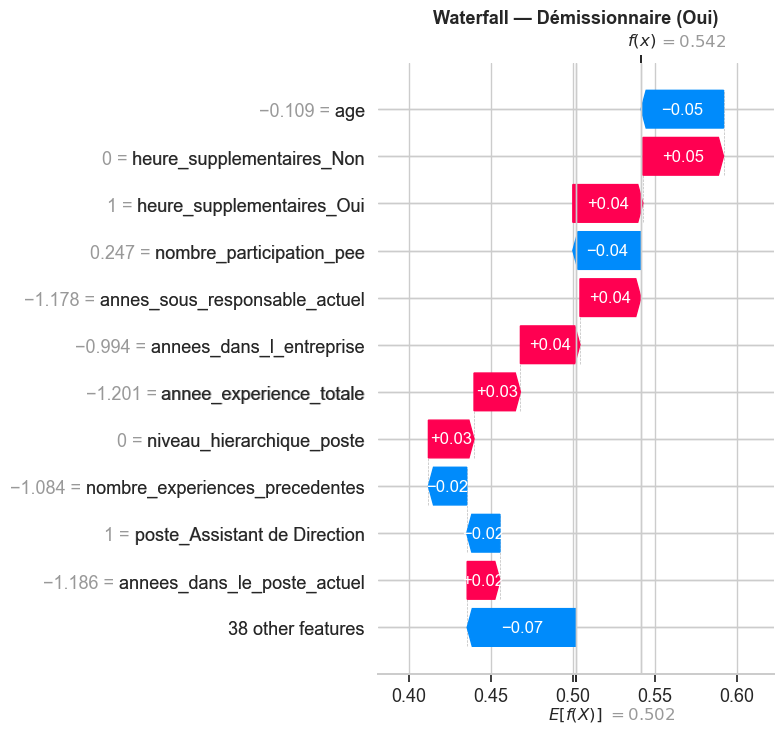

In [45]:
# Indices des vrais démissionnaires / restants dans le test
idx_partis = np.where(y_test.values == 1)[0]
idx_restes  = np.where(y_test.values == 0)[0]

# Réutilisation de shap_exp construit dans la cellule précédente
# Exemple 1 : un employé qui a quitté l'entreprise
print("=== Exemple 1 : Employé ayant quitté l'entreprise ===")
shap.plots.waterfall(shap_exp[idx_partis[0]], max_display=12, show=False)
plt.title('Waterfall — Démissionnaire (Oui)', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_shap_waterfall_parti.png', dpi=150, bbox_inches='tight')
plt.show()


=== Exemple 2 : Employé resté dans l'entreprise ===


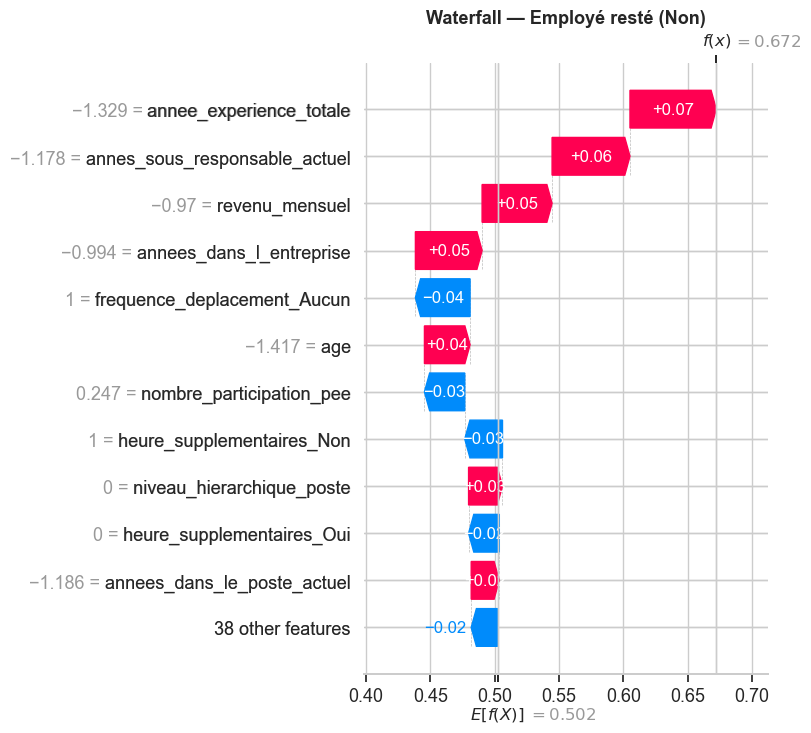

In [46]:
# Exemple 2 : un employé resté dans l'entreprise
print("=== Exemple 2 : Employé resté dans l'entreprise ===")
shap.plots.waterfall(shap_exp[idx_restes[0]], max_display=12, show=False)
plt.title('Waterfall — Employé resté (Non)', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/fig_shap_waterfall_reste.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Synthèse finale

| Étape | Livrable |
|-------|----------|
| EDA | Différences clés identifiées entre partis et restants |
| Feature Engineering | X et y prêts, encoding adapté à chaque type de feature |
| Baseline | 3 modèles comparés : Dummy < Régression Logistique < Random Forest |
| Gestion du déséquilibre | `class_weight='balanced'` vs SMOTE — comparaison CV + courbes PR + matrices de confusion |
| Modélisation avancée | RF pondéré + fine-tuning + seuil optimal |
| Interprétabilité | SHAP global (beeswarm) + local (waterfall) |